In [1]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
from scipy.signal import butter, filtfilt, hilbert
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

# 'Tom' provides the best baseline for measuring deep resonance vs sharp attack
TARGET_STROKE = "flam_mid" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

y, sr = librosa.load(wav_files[0], sr=44100)
y, _ = librosa.effects.trim(y, top_db=30)

In [2]:
def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

bands = {
    "Lows (20-250 Hz)": (20, 250),
    "Mids (250-2000 Hz)": (250, 2000),
    "Highs (2000+ Hz)": (2000, 15000)
}

filtered_signals = {}
for name, (low, high) in bands.items():
    filtered_signals[name] = butter_bandpass_filter(y, low, high, sr)

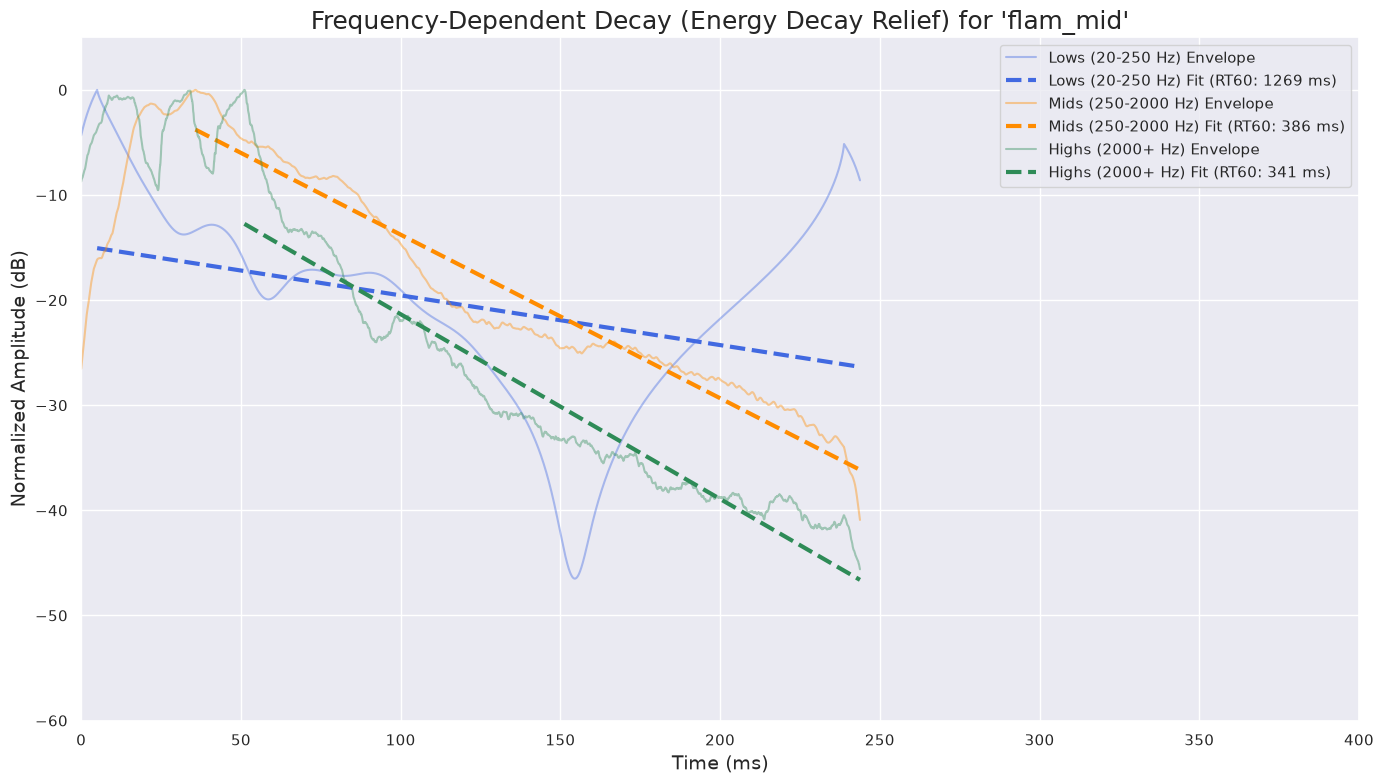

In [3]:
t = np.arange(len(y)) / sr * 1000  # Time in milliseconds
decay_stats = {}
envelopes_db = {}

fig, ax = plt.subplots(figsize=(14, 8))

colors = {"Lows (20-250 Hz)": "royalblue", "Mids (250-2000 Hz)": "darkorange", "Highs (2000+ Hz)": "seagreen"}

for name, signal in filtered_signals.items():
    # 1. Extract true amplitude envelope
    analytic_signal = hilbert(signal)
    amplitude_envelope = np.abs(analytic_signal)
    
    # Smooth the envelope (using a moving average to ignore micro-fluctuations)
    window_size = int(sr * 0.01) # 10ms window
    smoothed_env = np.convolve(amplitude_envelope, np.ones(window_size)/window_size, mode='same')
    
    # 2. Convert to Decibels
    env_db = 20 * np.log10(smoothed_env + 1e-7)
    
    # Normalize peak to 0 dB for fair comparison
    peak_idx = np.argmax(env_db)
    env_db_norm = env_db - env_db[peak_idx]
    envelopes_db[name] = env_db_norm
    
    # 3. Fit a line to the decay phase (from peak to ~300ms)
    tail_end_idx = min(len(env_db_norm), peak_idx + int(sr * 0.3)) 
    decay_slice = env_db_norm[peak_idx:tail_end_idx]
    t_slice = t[peak_idx:tail_end_idx]
    
    # Polyfit returns [slope, intercept]
    # Slope is dB per millisecond
    slope, intercept = np.polyfit(t_slice, decay_slice, 1)
    
    # Convert slope to RT60 proxy (time to decay 60dB)
    rt60 = -60 / slope if slope < 0 else 0
    decay_stats[name] = {"slope_db_ms": slope, "rt60_ms": rt60}
    
    # 4. Plot Envelope and Fitted Line
    ax.plot(t, env_db_norm, color=colors[name], alpha=0.4, label=f"{name} Envelope")
    ax.plot(t_slice, (slope * t_slice) + intercept, color=colors[name], linewidth=3, linestyle="--", 
            label=f"{name} Fit (RT60: {rt60:.0f} ms)")

ax.set_title(f"Frequency-Dependent Decay (Energy Decay Relief) for '{TARGET_STROKE}'", fontsize=18)
ax.set_xlabel("Time (ms)", fontsize=14)
ax.set_ylabel("Normalized Amplitude (dB)", fontsize=14)
ax.set_xlim(0, 400)
ax.set_ylim(-60, 5)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [4]:
print("--- Envelope Parameters for Synthesis ---")
for name, stats in decay_stats.items():
    print(f"{name}:")
    print(f"  Decay Rate: {stats['slope_db_ms']:.2f} dB/ms")
    print(f"  T60 (Time to -60dB): {stats['rt60_ms']:.0f} ms\n")

--- Envelope Parameters for Synthesis ---
Lows (20-250 Hz):
  Decay Rate: -0.05 dB/ms
  T60 (Time to -60dB): 1269 ms

Mids (250-2000 Hz):
  Decay Rate: -0.16 dB/ms
  T60 (Time to -60dB): 386 ms

Highs (2000+ Hz):
  Decay Rate: -0.18 dB/ms
  T60 (Time to -60dB): 341 ms

